# Phase 4: Trench filling and voids

This is a 2D side view of a wafer with a rectangular trench etched into it. Each cell is empty, substrate or film.
* **Sticky ballistic deposition**: atoms fall straight down and stop as soon as they touch any filled cell, either below or beside them. Atoms grazing the trench's top corners stick to the side of the corner, so overhangs grow inward.
* **Thermal hopping**: the newly arrived atom gets `hops` attempts. Each succeeds with probability exp(-n x epsilon), where n is the number of filled neighbours. A successful hop moves the atom to the neighbouring empty cell with the most bonds.
* **Voids**: a breadth-first flood fill starts from the open space above. Empty cells it cannot reach are sealed voids.
* **Step coverage** = film on the trench bottom / film on top.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML

In [2]:
from dataclasses import asdict
from thin_film import trench as tr
from thin_film.plotting import plot_trench, plot_sweep, animate_trench, trench_image
base = tr.TrenchSettings()
base

TrenchSettings(width=128, trench_width=12, trench_depth=16, base=3, n_monolayers=24, temperature=300.0, flux=1.0, e_bond=0.1, e_diff=0.8, nu0=10000000000000.0, max_hops=3000, n_runs=6, seed=42)

## 1. Void detection on a hand-made example

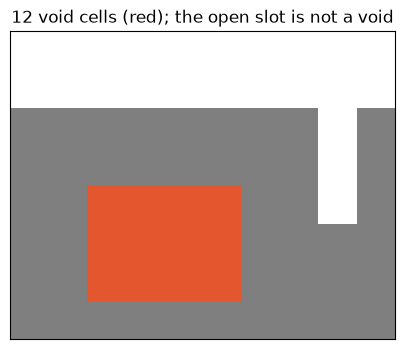

In [3]:
g = np.zeros((8, 10), np.int8); g[:6] = tr.SUBSTRATE
g[1:4, 2:6] = tr.EMPTY      # sealed pocket
g[3:6, 8] = tr.EMPTY        # open slot
v = tr.find_voids(g)
plot_trench(g, v, crop_top=False, title=f"{v.sum()} void cells (red); the open slot is not a void"); plt.show()

## 2. Cold vs hot

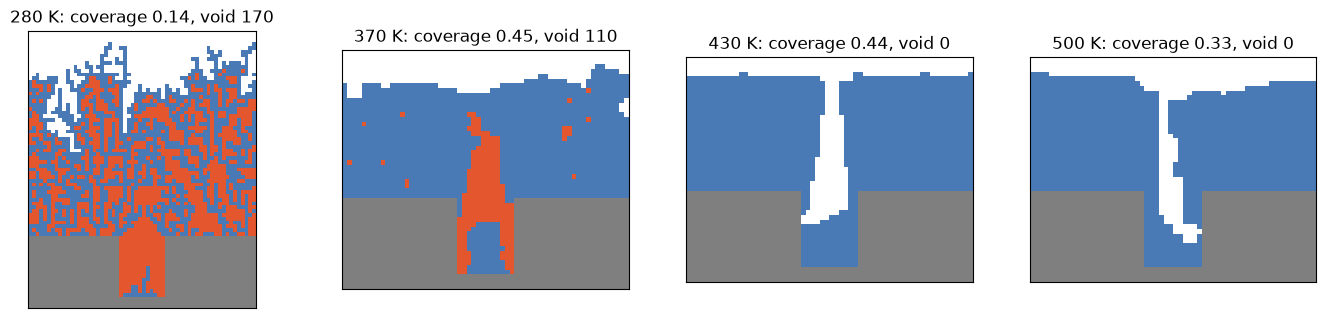

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, T in zip(axes, (280, 370, 430, 500)):
    s = tr.TrenchSettings(**{**asdict(base), "temperature": T}); g = tr.grow(s); m = tr.measure(g, s)
    x0, x1 = s.trench_x
    plot_trench(g[:, x0-24:x1+24], tr.find_voids(g)[:, x0-24:x1+24], ax=ax,
                title=f"{T} K: coverage {m['step_coverage']:.2f}, void {m['trench_void_area']}")
plt.show()

* **280 K**: the film is sticky and porous (red pores everywhere), and the trench seals almost immediately.
* **370 K**: the film is dense, but overhangs still close over a void.
* **430 K and above**: atoms reach the trench corners and the trench fills from the bottom. A narrow seam can stay open to the surface. It is not counted as a void because it is not sealed.

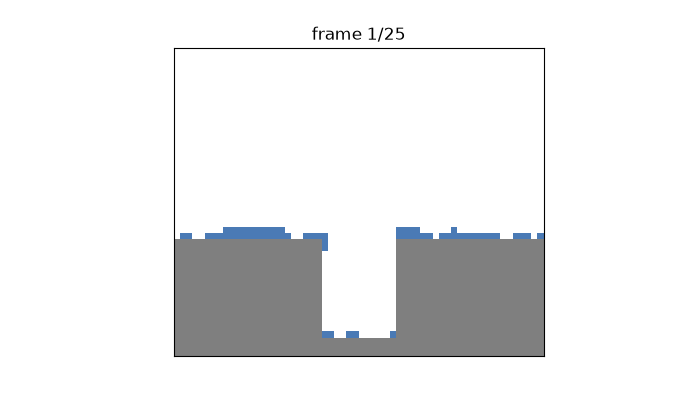

In [5]:
from thin_film.plotting import gif_bytes
from IPython.display import Image
# Animate one 370 K run: deposit in 25 chunks, snapshot after each (voids in red)
s = tr.TrenchSettings(**{**asdict(base), "temperature": 370})
grid, (eps, hops) = tr.make_trench(s), s.thermal()
x0, x1 = s.trench_x
frames = []
for k in range(25):
    tr.deposit(grid, int(s.n_monolayers * s.width / 25), eps, hops, k)
    frames.append(trench_image(grid, tr.find_voids(grid))[:, x0 - 24: x1 + 24])
anim = animate_trench(frames); plt.close()
Image(data=gif_bytes(anim))

## 3. Temperature sweep (trench 12 wide x 16 deep)

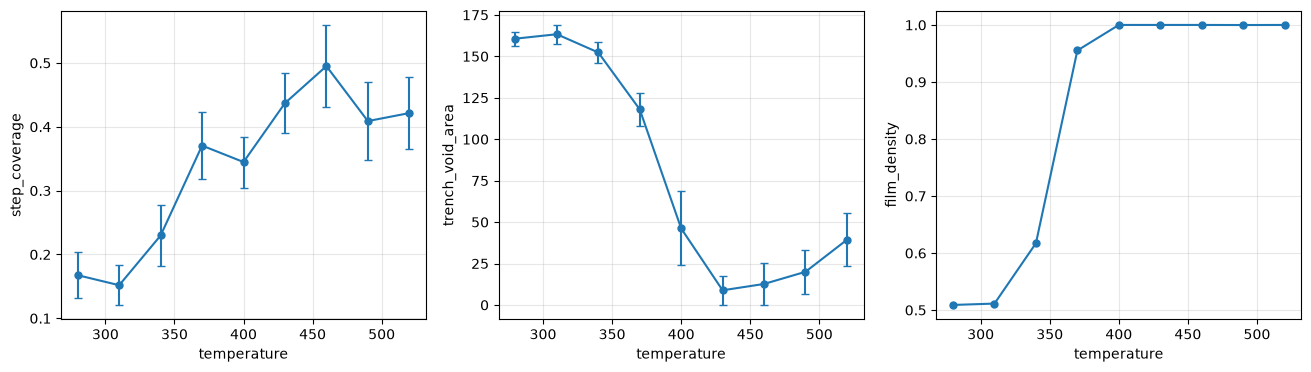

,temperature,epsilon,hops_per_atom,step_coverage,trench_void_area,void_probability,film_density
0,280,4.144,0.040,0.168,160.667,1.000,0.509
1,310,3.743,0.987,0.152,163.333,1.000,0.511
2,340,3.413,13.858,0.230,152.333,1.000,0.617
3,370,3.136,126.818,0.371,118.000,1.000,0.955
4,400,2.901,832.614,0.345,46.167,0.500,1.000
5,430,2.699,3000.000,0.437,8.833,0.167,1.000
6,460,2.523,3000.000,0.495,12.667,0.167,1.000
7,490,2.368,3000.000,0.409,20.000,0.333,1.000
8,520,2.232,3000.000,0.421,39.333,0.667,1.000


In [6]:
t_df = tr.sweep(base, "temperature", np.arange(280, 521, 30))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_sweep(t_df, "temperature", "step_coverage", "step_coverage_sem", ax=axes[0])
plot_sweep(t_df, "temperature", "trench_void_area", "trench_void_area_sem", ax=axes[1])
plot_sweep(t_df, "temperature", "film_density", ax=axes[2]); plt.show()
t_df[["temperature", "epsilon", "hops_per_atom", "step_coverage", "trench_void_area", "void_probability", "film_density"]].round(3)

Above about 460 K the void area creeps back up. This comes from the hop cap. Hops are capped at 3000 per atom (marked "capped" in the app), so above roughly 425 K extra heat no longer adds hops, but it keeps weakening bonds (epsilon falls). Atoms then leave the corners they would otherwise fill. A higher `max_hops` pushes this upturn to higher temperatures, at the cost of longer runs.

## 4. Trench-width sweep

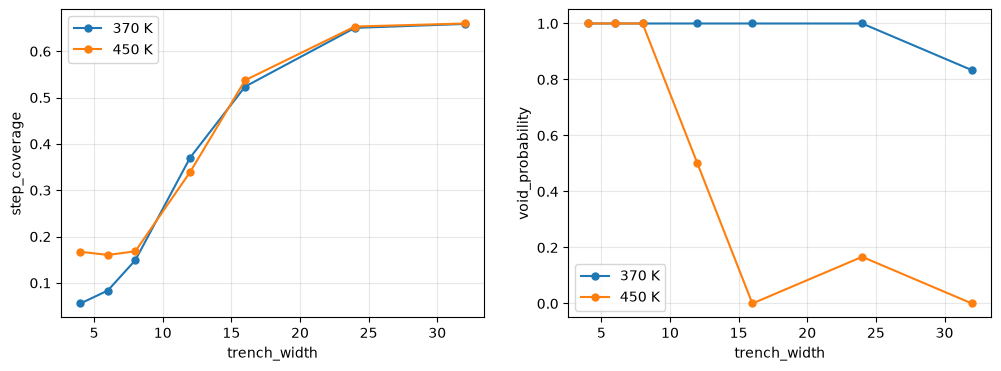

In [7]:
w_df = pd.concat([tr.sweep(tr.TrenchSettings(**{**asdict(base), "temperature": T}), "trench_width", [4, 6, 8, 12, 16, 24, 32]).assign(temperature=T)
                  for T in (370, 450)])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for T, d in w_df.groupby("temperature"):
    plot_sweep(d, "trench_width", "step_coverage", ax=axes[0], label=f"{T} K")
    plot_sweep(d, "trench_width", "void_probability", ax=axes[1], label=f"{T} K")
for ax in axes: ax.legend()
plt.show()

## Takeaways
* Narrow trenches (high aspect ratio) trap voids at every temperature. The overhangs from the two corners meet before atoms can reach the bottom.
* Heating removes voids for trenches about 16 cells wide and wider (aspect ratio 1 or less), and roughly triples step coverage compared with cold deposition.
* This is the trade-off behind real fab practice: high-aspect-ratio features need more than line-of-sight deposition (for example reflow, ALD or electroplating with additives).